In [2]:
!pip install requests pandas


[notice] A new release of pip is available: 25.3 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import requests
import pandas as pd

LISTS_URL = "https://www.bankofcanada.ca/valet/lists/series/json"

def get_all_series():
    resp = requests.get(LISTS_URL, timeout=30)
    resp.raise_for_status()
    data = resp.json()
    series = data.get("series", {})
    rows = []
    for name, info in series.items():
        rows.append({
            "name": name,
            "label": info.get("label", ""),
            "description": info.get("description", ""),
        })
    return pd.DataFrame(rows)

def search_series(df, keywords):
    pattern = "|".join(keywords)
    mask = (
        df["label"].str.contains(pattern, case=False, na=False)
        | df["description"].str.contains(pattern, case=False, na=False)
    )
    return df[mask]

all_series = get_all_series()
print(f"Total series available: {len(all_series)}")

Total series available: 15914


In [4]:
search_series(all_series, ["overnight", "policy rate", "bank rate"])

,name,label,description
252,AVG.INTWO,Canadian Overnight Repo Rate Average (CORRA) (%),Canadian Overnight Repo Rate Average (CORRA) (%)
1252,BR.CDN,STATIC_BANKRATE,Bank Rate
1263,CBC20210,V39079,Target for the overnight rate
3161,CL.CDN.MOST.1DL,Overnight money market financing rate,An estimate of the collateralized overnight ra...
3334,CORRA_WEIGHTED_MEAN_RATE,CORRA: Mean,The volume‑weighted average rate of eligible o...
...,...,...,...
12924,V122530,V122530,Bank rate
14025,V39078,V39078,Bank rate
14026,V39079,Target for the overnight rate (business daily),"Also called the policy interest rate, the aver..."
14667,V80691310,V80691310,Bank rate


In [5]:
search_series(all_series, ["5-year mortgage", "conventional mortgage", "posted mortgage"])

,name,label,description
12881,V121763,V80691333,Conventional mortgage - 1-year
12882,V121764,V80691335,Conventional mortgage - 5-year
12884,V121769,V80691334,Conventional mortgage - 3-year
12916,V122520,V122520,Conventional mortgage - 1-year
12917,V122521,V122521,Conventional mortgage - 5-year
12918,V122522,V122522,Conventional mortgage - 3-year
14669,V80691333,Conventional mortgage: 1-year,The interest rate for a 1-year conventional mo...
14670,V80691334,Conventional mortgage: 3-year,The interest rate for a 3-year conventional mo...
14671,V80691335,Conventional mortgage: 5-year,The interest rate for a 5-year conventional mo...
15267,WM_SAN_BILO20181003_C1_S4,5-year mortgage rate (left scale),Share of new mortgages with a loan-to-income r...


In [6]:
search_series(all_series, ["CPI-trim", "CPI-median", "CPI-common", "All-items CPI"])

,name,label,description
3342,CPI_COMMON,CPI-common,The monthly value of the common component of C...
3343,CPI_MEDIAN,CPI-median,The monthly value of the median Consumer Price...
3344,CPI_TRIM,CPI-trim,The monthly value of the trim component of the...
5836,INDINF_CPI_COMMON_M,CPI-common,The monthly value of the common component of C...
5837,INDINF_CPI_COMMON_Q,CPI-common,The quarterly value of the common component of...
5839,INDINF_CPI_MEDIAN_M,CPI-median,The monthly value of the median Consumer Price...
5840,INDINF_CPI_MEDIAN_Q,CPI-median,The quarterly value of the median Consumer Pri...
5842,INDINF_CPI_TRIM_M,CPI-trim,The monthly value of the trim component of the...
5843,INDINF_CPI_TRIM_Q,CPI-trim,The quarterly value of the trim component of t...
6301,MPR_2024M10_CPI_YOY_S2,CPI-median,


In [7]:
search_series(all_series, ["arrears", "delinquen", "default"])

,name,label,description
3889,DEBT_ARREARS_DEFRATE_CONV_DEF_2025,ARREARS_DEFRATE_CONV_DEF_2025,ARREARS_DEFRATE_CONV_DEF_2025
3890,DEBT_ARREARS_DEFRATE_SOVEREIGNS_2025,ARREARS_DEFRATE_SOVEREIGNS_2025,ARREARS_DEFRATE_SOVEREIGNS_2025
3891,DEBT_ARREARS_DEFRATE_WORLD_GDP_2025,ARREARS_DEFRATE_WORLD_GDP_2025,ARREARS_DEFRATE_WORLD_GDP_2025
3892,DEBT_ARREARS_TOTAL_SOVEREIGNS_2021,ARREARS_TOTAL_SOVEREIGNS_2021,ARREARS_TOTAL_SOVEREIGNS_2021
3893,DEBT_ARREARS_TOTAL_SOVEREIGNS_2022,ARREARS_TOTAL_SOVEREIGNS_2022,ARREARS_TOTAL_SOVEREIGNS_2022
3894,DEBT_ARREARS_TOTAL_SOVEREIGNS_2023,ARREARS_TOTAL_SOVEREIGNS_2023,ARREARS_TOTAL_SOVEREIGNS_2023
3895,DEBT_ARREARS_TOTAL_SOVEREIGNS_2024,ARREARS_TOTAL_SOVEREIGNS_2024,ARREARS_TOTAL_SOVEREIGNS_2024
3896,DEBT_ARREARS_TOTAL_SOVEREIGNS_2025,ARREARS_TOTAL_SOVEREIGNS_2025,ARREARS_TOTAL_SOVEREIGNS_2025
3981,DEBT_FISCAL_ARREARS_2020,FISCAL_ARREARS_2020,FISCAL_ARREARS_2020
3982,DEBT_FISCAL_ARREARS_2021,FISCAL_ARREARS_2021,FISCAL_ARREARS_2021


In [8]:
search_series(all_series, ["household credit", "consumer credit", "credit growth"])

,name,label,description
3308,CONSCRED_12MTH,Consumer credit (Year-over-year growth rates),Household credit - Household credit (Year-over...
3309,CONSCRED_ANN_3MTH,Consumer credit (Annualized 3-month growth rates),Household credit - Household credit (Annualize...
4341,FSHUB_20210317_C8_S1,"Consumer credit, including home equity lines o...",
4343,FSHUB_20210317_C8_S3,Total household credit,
4403,FSR_2017Jun_c2s2,FSR_2017Jun_c2s2,"June 2017 FSR; Chart 2; Consumer credit, exclu..."
...,...,...,...
13071,V122746,Total residential mortgage credit (Seasonally ...,Household credit - Residential mortgage credit
13072,V122748,Chartered banks (Seasonally adjusted),Household credit - Residential mortgage credit
13073,V122754,Of which: NHA mortgage-backed securities (Seas...,Household credit - Residential mortgage credit...
13754,V36408,Total household credit (Unadjusted),Household credit


In [9]:
import requests
import pandas as pd

series_ids = {
    "arrears_cc": "FVI_LOANS_ARR_CC",
    "overnight_rate": "V39079",
    "mortgage_5yr": "V80691335",
    "cpi_trim": "CPI_TRIM",
    "household_credit": "V36415",
}

results = {}

for key, series_id in series_ids.items():
    url = f"https://www.bankofcanada.ca/valet/observations/{series_id}/json"
    resp = requests.get(url)
    data = resp.json()
    obs = data["observations"]
    print(f"{key} ({series_id}): {len(obs)} observations, {obs[0]['d']} to {obs[-1]['d']}")
    results[key] = obs

arrears_cc (FVI_LOANS_ARR_CC): 45 observations, 2015-01-01 to 2026-01-01
overnight_rate (V39079): 4507 observations, 2009-04-21 to 2026-08-18
mortgage_5yr (V80691335): 2695 observations, 1975-01-01 to 2026-08-19
cpi_trim (CPI_TRIM): 379 observations, 1995-01-01 to 2026-07-01
household_credit (V36415): 621 observations, 1969-01-01 to 2020-09-01


In [10]:
search_series(all_series, ["household credit", "total household"])

,name,label,description
1350,CES_2022Q1_C9_S1,Expected change in spending for those who feel...,"Over the next 12 months, by what percent do yo..."
1351,CES_2022Q1_C9_S2,Expected change in spending for those who feel...,"Over the next 12 months, by what percent do yo..."
2750,CES_C5G_INCOME_OH,"Expected income growth, next 12 months, homeowner","Income growth: Over the next 12 months, by abo..."
2751,CES_C5G_INCOME_R,"Expected income growth, next 12 months, renter","Income growth: Over the next 12 months, by abo..."
2752,CES_C5G_SPENDING_OH,"Expected spending growth, next 12 months, home...","Income growth: Over the next 12 months, by abo..."
2753,CES_C5G_SPENDING_R,"Expected spending growth, next 12 months, rent...","Income growth: Over the next 12 months, by abo..."
2754,CES_C5H_INCOME_NC,"Expected income growth, next 12 months, newcomer","Income growth: Over the next 12 months, by abo..."
2755,CES_C5H_INCOME_NN,"Expected income growth, next 12 months, non-ne...","Income growth: Over the next 12 months, by abo..."
2756,CES_C5H_SPENDING_NC,"Expected spending growth, next 12 months, newc...","Income growth: Over the next 12 months, by abo..."
2757,CES_C5H_SPENDING_NN,"Expected spending growth, next 12 months, non-...","Income growth: Over the next 12 months, by abo..."


In [11]:
import pandas as pd

final_series = {
    "arrears_cc": "FVI_LOANS_ARR_CC",
    "overnight_rate": "V39079",
    "mortgage_5yr": "V80691335",
    "cpi_trim": "CPI_TRIM",
}

dataframes = {}

for key, series_id in final_series.items():
    url = f"https://www.bankofcanada.ca/valet/observations/{series_id}/json"
    resp = requests.get(url)
    data = resp.json()
    obs = data["observations"]
    
    df = pd.DataFrame(obs)
    df["date"] = pd.to_datetime(df["d"])
    df["value"] = df[series_id].apply(lambda x: float(x["v"]) if isinstance(x, dict) else None)
    df = df[["date", "value"]].rename(columns={"value": key})
    df = df.set_index("date")
    
    dataframes[key] = df
    print(f"{key}: {df.shape[0]} rows, {df.index.min()} to {df.index.max()}")

arrears_cc: 45 rows, 2015-01-01 00:00:00 to 2026-01-01 00:00:00
overnight_rate: 4507 rows, 2009-04-21 00:00:00 to 2026-08-18 00:00:00
mortgage_5yr: 2695 rows, 1975-01-01 00:00:00 to 2026-08-19 00:00:00
cpi_trim: 379 rows, 1995-01-01 00:00:00 to 2026-07-01 00:00:00


In [12]:
overnight_q = dataframes["overnight_rate"].resample("QS").mean()
mortgage_q = dataframes["mortgage_5yr"].resample("QS").mean()
cpi_q = dataframes["cpi_trim"].resample("QS").mean()
arrears_q = dataframes["arrears_cc"]  # already quarterly, no resampling needed

# Merge all 4 into one dataframe, aligned by date
merged = arrears_q.join([overnight_q, mortgage_q, cpi_q], how="inner")

print(f"Merged shape: {merged.shape}")
print(f"Date range: {merged.index.min()} to {merged.index.max()}")
merged.head(10)

Merged shape: (45, 4)
Date range: 2015-01-01 00:00:00 to 2026-01-01 00:00:00


,arrears_cc,overnight_rate,mortgage_5yr,cpi_trim
date,,,,
2015-01-01,0.52,0.804688,4.769167,1.633333
2015-04-01,0.53,0.750000,4.647692,1.466667
2015-07-01,0.57,0.537879,4.640000,1.666667
2015-10-01,0.58,0.500000,4.640000,1.766667
2016-01-01,0.60,0.500000,4.640000,1.800000
2016-04-01,0.62,0.500000,4.640000,1.933333
2016-07-01,0.63,0.500000,4.709231,1.866667
2016-10-01,0.64,0.500000,4.640000,1.666667
2017-01-01,0.64,0.500000,4.640000,1.500000


C:\Users\izank\AppData\Local\Temp\ipykernel_22632\4052684058.py:28: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axes[0].legend(loc="upper left", fontsize=8)


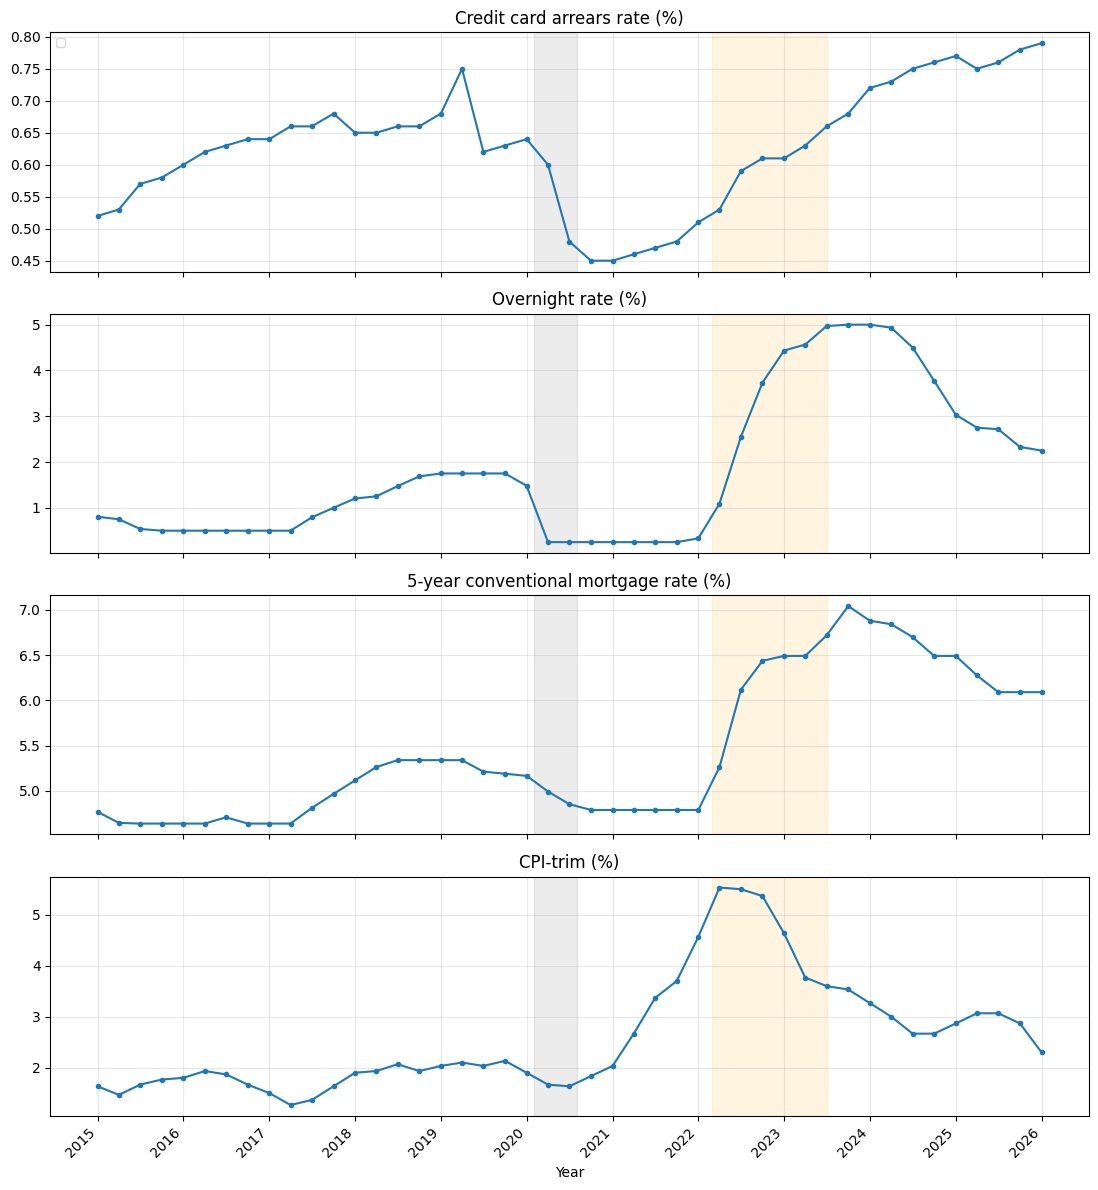

                arrears_cc  overnight_rate  mortgage_5yr  cpi_trim
arrears_cc           1.000           0.589         0.614    -0.050
overnight_rate       0.589           1.000         0.968     0.493
mortgage_5yr         0.614           0.968         1.000     0.551
cpi_trim            -0.050           0.493         0.551     1.000


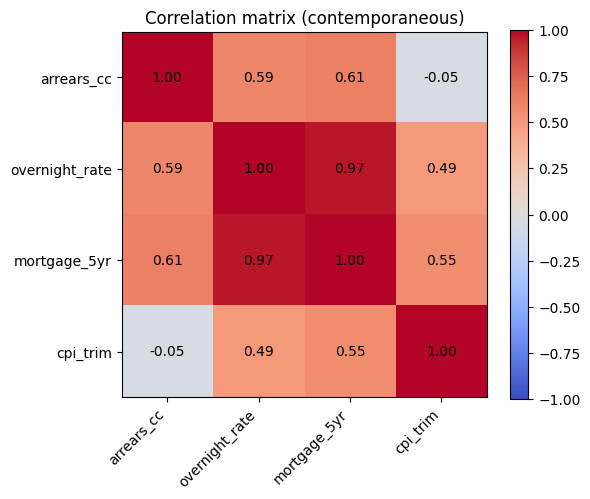

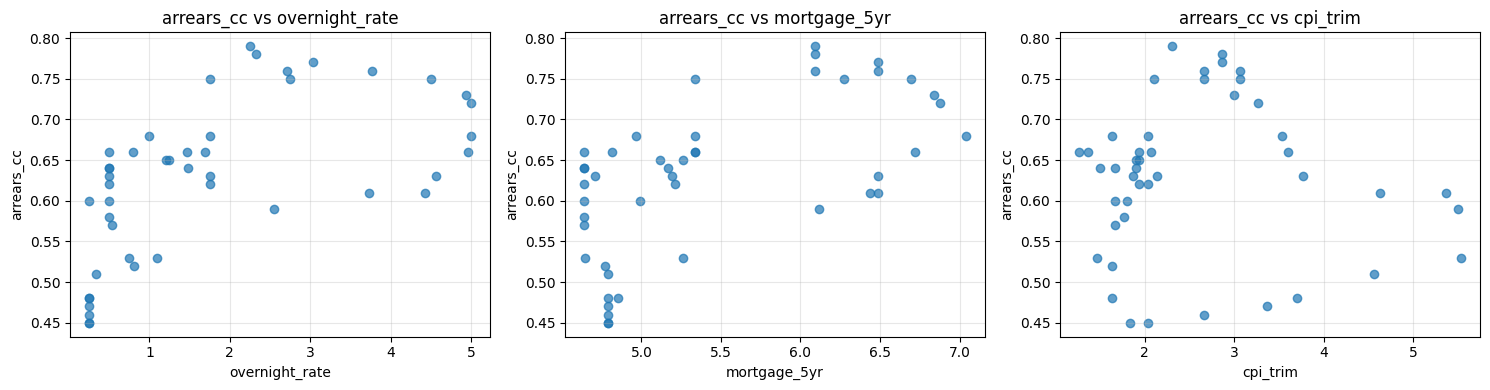

                count      mean       std       min   25%       50%       75%  \
arrears_cc       45.0  0.628667  0.095002  0.450000  0.58  0.640000  0.680000   
overnight_rate   45.0  1.804159  1.593198  0.250000  0.50  1.250000  2.715909   
mortgage_5yr     45.0  5.439513  0.794976  4.640000  4.79  5.190000  6.116923   
cpi_trim         45.0  2.594815  1.135024  1.266667  1.80  2.066667  3.066667   

                     max  
arrears_cc      0.790000  
overnight_rate  5.000000  
mortgage_5yr    7.040000  
cpi_trim        5.533333  


In [18]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

# --- 1. Time series plots ---
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

fig, axes = plt.subplots(4, 1, figsize=(11, 12), sharex=True)

series_plot = {
    "arrears_cc": "Credit card arrears rate (%)",
    "overnight_rate": "Overnight rate (%)",
    "mortgage_5yr": "5-year conventional mortgage rate (%)",
    "cpi_trim": "CPI-trim (%)",
}

for ax, (col, title) in zip(axes, series_plot.items()):
    ax.plot(merged.index, merged[col], marker="o", markersize=3)
    ax.set_title(title)
    ax.axvspan(pd.Timestamp("2020-02-01"), pd.Timestamp("2020-08-01"), color="grey", alpha=0.15)
    ax.axvspan(pd.Timestamp("2022-03-01"), pd.Timestamp("2023-07-01"), color="orange", alpha=0.12)
    ax.grid(alpha=0.3)
    ax.xaxis.set_major_locator(mdates.YearLocator())
    ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right")

axes[-1].set_xlabel("Year")
axes[0].legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()


# --- 2. Correlation matrix ---
corr = merged.corr()
print(corr.round(3))

fig, ax = plt.subplots(figsize=(6, 5))
im = ax.imshow(corr, cmap="coolwarm", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr.columns)))
ax.set_yticks(range(len(corr.columns)))
ax.set_xticklabels(corr.columns, rotation=45, ha="right")
ax.set_yticklabels(corr.columns)
for i in range(len(corr.columns)):
    for j in range(len(corr.columns)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", color="black")
fig.colorbar(im)
ax.set_title("Correlation matrix (contemporaneous)")
plt.tight_layout()
plt.show()


# --- 3. Scatter plots: arrears vs each predictor ---
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

predictors = ["overnight_rate", "mortgage_5yr", "cpi_trim"]
for ax, col in zip(axes, predictors):
    ax.scatter(merged[col], merged["arrears_cc"], alpha=0.7)
    ax.set_xlabel(col)
    ax.set_ylabel("arrears_cc")
    ax.set_title(f"arrears_cc vs {col}")
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()


# --- 4. Summary stats ---
print(merged.describe().T)

In [19]:
import pandas as pd

lags_to_test = [1, 2, 3, 4]  # quarters
target = merged["arrears_cc"]

lag_results = []
for col in ["overnight_rate", "mortgage_5yr", "cpi_trim"]:
    for lag in lags_to_test:
        lagged_series = merged[col].shift(lag)
        corr = target.corr(lagged_series)
        lag_results.append({"variable": col, "lag_quarters": lag, "correlation": round(corr, 3)})

lag_df = pd.DataFrame(lag_results)
pivot = lag_df.pivot(index="variable", columns="lag_quarters", values="correlation")

# Add lag 0 (contemporaneous) for comparison
pivot.insert(0, 0, [merged[col].corr(target) for col in pivot.index])
pivot = pivot.round(3)
print(pivot)

lag_quarters        0      1      2      3      4
variable                                         
cpi_trim       -0.050  0.067  0.157  0.237  0.306
mortgage_5yr    0.614  0.639  0.644  0.645  0.627
overnight_rate  0.589  0.649  0.670  0.661  0.642


In [20]:
lags_to_test = list(range(0, 8))  # test out to 2 years back
target = merged["arrears_cc"]

lag_results = []
for lag in lags_to_test:
    lagged_series = merged["mortgage_5yr"].shift(lag)
    corr = target.corr(lagged_series)
    lag_results.append({"lag_quarters": lag, "correlation": round(corr, 3)})

lag_df = pd.DataFrame(lag_results)
print(lag_df)

   lag_quarters  correlation
0             0        0.614
1             1        0.639
2             2        0.644
3             3        0.645
4             4        0.627
5             5        0.587
6             6        0.534
7             7        0.467


In [23]:
from statsmodels.tsa.stattools import adfuller

for col in merged.columns:
    result = adfuller(merged[col].dropna())
    print(f"{col}: ADF stat={result[0]:.3f}, p-value={result[1]:.4f}")

arrears_cc: ADF stat=-0.895, p-value=0.7895
overnight_rate: ADF stat=-2.163, p-value=0.2198
mortgage_5yr: ADF stat=-1.052, p-value=0.7337
cpi_trim: ADF stat=-2.390, p-value=0.1447


In [24]:
import statsmodels.api as sm
import pandas as pd

# Build lagged predictor
data = merged.copy()
data["mortgage_5yr_lag3"] = data["mortgage_5yr"].shift(3)
data = data.dropna(subset=["mortgage_5yr_lag3", "arrears_cc"])

print(f"Usable rows after lagging: {len(data)}")

# Fit the regression
X = sm.add_constant(data["mortgage_5yr_lag3"])
y = data["arrears_cc"]
model = sm.OLS(y, X).fit()

print(model.summary())

Usable rows after lagging: 42
                            OLS Regression Results                            
Dep. Variable:             arrears_cc   R-squared:                       0.416
Model:                            OLS   Adj. R-squared:                  0.401
Method:                 Least Squares   F-statistic:                     28.47
Date:                Wed, 19 Aug 2026   Prob (F-statistic):           4.04e-06
Time:                        19:14:45   Log-Likelihood:                 51.038
No. Observations:                  42   AIC:                            -98.08
Df Residuals:                      40   BIC:                            -94.60
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                        coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------
const   

In [25]:
from statsmodels.tsa.stattools import adfuller

merged_diff = merged.diff().dropna()

print(f"Rows after differencing: {len(merged_diff)}")
print()

for col in merged_diff.columns:
    result = adfuller(merged_diff[col])
    print(f"{col}: ADF stat={result[0]:.3f}, p-value={result[1]:.4f}")

Rows after differencing: 44

arrears_cc: ADF stat=-5.820, p-value=0.0000
overnight_rate: ADF stat=-4.729, p-value=0.0001
mortgage_5yr: ADF stat=-3.216, p-value=0.0191
cpi_trim: ADF stat=-2.987, p-value=0.0362


In [26]:
import statsmodels.api as sm

# Difference first, then lag the predictor by 3 quarters
data = merged.diff()
data["mortgage_5yr_lag3_diff"] = data["mortgage_5yr"].shift(3)
data = data.dropna(subset=["mortgage_5yr_lag3_diff", "arrears_cc"])

print(f"Usable rows: {len(data)}")

X = sm.add_constant(data["mortgage_5yr_lag3_diff"])
y = data["arrears_cc"]
model = sm.OLS(y, X).fit()

print(model.summary())

Usable rows: 41
                            OLS Regression Results                            
Dep. Variable:             arrears_cc   R-squared:                       0.021
Model:                            OLS   Adj. R-squared:                 -0.004
Method:                 Least Squares   F-statistic:                    0.8479
Date:                Wed, 19 Aug 2026   Prob (F-statistic):              0.363
Time:                        19:24:10   Log-Likelihood:                 79.150
No. Observations:                  41   AIC:                            -154.3
Df Residuals:                      39   BIC:                            -150.9
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                             coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------------
const       